In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hw6_exercise_1.ipynb")

# CPSC 330 - Applied Machine Learning 

## Homework 6: Clustering (Exercise 1)
### Associated lectures: [Chapters 14 and 15](https://ubc-cs.github.io/cpsc330-book/)

**Due date: See the course website for deliverable due dates**.

## Imports <a name="im"></a>

In [15]:
import os
from hashlib import sha1

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.cluster import KMeans
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer

%matplotlib inline
pd.set_option("display.max_colwidth", 0)

<br><br><br><br>

<!-- BEGIN QUESTION -->

<div class="alert alert-info">
    
## Instructions
rubric={points}

You will earn points for following these instructions and successfully submitting your work in PrairieLearn.

### Group work instructions

**You may work with a partner on this homework and submit your assignment as a group.** Below are some instructions on working as a group.
- The maximum group size is 2.
- Use group work as an opportunity to collaborate and learn new things from each other.
- Be respectful to each other and make sure you understand all the concepts in the assignment well.
- It is your responsibility to make sure your PrairieLearn group is set up correctly and that the assignment is submitted before the deadline.

### General submission instructions

- Please **read carefully [Use of Generative AI policy](https://ubc-cs.github.io/cpsc330-2026W1/syllabus/#use-of-generative-ai-genai)** before starting the homework assignment.
- **Run all cells before submitting:** Go to `Kernel -> Restart Kernel and Clear All Outputs`, then select `Run -> Run All Cells`. This ensures your notebook runs cleanly from start to finish without errors.
- **Save your work in JupyterLab:** Make sure `hw6_exercise_1.ipynb` is saved.
- **Check your saved submission in PrairieLearn:** Return to the PrairieLearn question page and click **Save only** to capture your notebook and review the preview. When you are ready to submit for grading, click **Save & Grade**.
- **Check that outputs render properly:** Make sure all plots and outputs appear in the notebook preview.
- **Keep execution order clean:** Execution numbers should start at "1" and increase in order. Out-of-order or missing execution numbers may result in mark deductions.
- **Follow course submission guidelines:** Review the CPSC 330 homework instructions for detailed guidance on completing and submitting assignments.

</div>

_Points:_ 4

<!-- END QUESTION -->

<br><br><br><br>

## Exercise 1: Document clustering warm-up
<hr>

In this homework, we will explore a popular application of clustering called [**document clustering**](https://en.wikipedia.org/wiki/Document_clustering). A large amount of unlabeled text data is available out there (e.g., news, recipes, online Q&A, tweets), and clustering is a commonly used technique to organize this data in a meaningful way. 

As a warm up, in this exercise you will cluster sentences from a toy corpus. Later in the homework you will work with a real corpus. 

The code below extracts introductory sentences of Wikipedia articles on a set of queries. To run the code successfully, you will need the `wikipedia` package installed in the course environment. 

```
conda activate cpsc330
conda install -c conda-forge wikipedia
```


**Your tasks:**

Run the code below which 
- extracts content of Wikipedia articles on a set of queries
- tokenizes the text (i.e., separates sentences) and 
- stores the 2nd sentence in each article as a document representing that article

> Feel free to experiment with Wikipedia queries of your choice. But stick to the provided list for the final submission so that it's easier for the TAs to grade your submission.

> For tokenization we are using the `nltk` package. If you do not have this package in the course environment, you will have to install it.

```
conda activate cpsc330
conda install -c anaconda nltk
```

Even if you have the package installed via the course `conda` environment, you might have to download `nltk` pre-trained models, which can be done with the code below.

In [3]:
import nltk

nltk.download("punkt")
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /Users/johnn/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /Users/johnn/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [6]:
import wikipedia
wikipedia.wikipedia.USER_AGENT = "CPSC330-homework (jzhao19@student.ubc.ca)"
import string
from nltk.tokenize import sent_tokenize, word_tokenize

queries = [
    "Artificial Intelligence",
    "Deep learning",
    "Unsupervised learning",
    "Quantum Computer",
    "Environmental protection",
    "Climate Change",
    "Green energy",
    "Biodiversity",
    "French Cuisine",
    "Bread food",
    "Dumpling food",
]
wiki_dict = {"wiki query": [], "text": [], "n_words": []}
remove_tokens = list(string.punctuation) + ['``', '’', '`', 'br', '"', "”", "''", "'s", "(", ")", "[", "]"]

# Running this code might take some time.
for query in queries:
    try:
        # Attempt to fetch the page content
        page_content = wikipedia.page(query).content
    except wikipedia.exceptions.PageError:
        print(f"Page not found for query: {query}. Skipping...")
        continue
    except wikipedia.exceptions.DisambiguationError as e:
        print(f"Query: {query} led to a disambiguation page. Choosing the first option: {e.options[0]}")
        page_content = wikipedia.page(e.options[0]).content

    text = sent_tokenize(page_content)[0]
    tokenized = word_tokenize(text)
    text_pp = [token.lower() for token in tokenized if token.lower() not in remove_tokens]
    wiki_dict["n_words"].append(len(text_pp))
    wiki_dict["text"].append(" ".join(text_pp))
    wiki_dict["wiki query"].append(query)

wiki_df = pd.DataFrame(wiki_dict)
wiki_df

Page not found for query: Dumpling food. Skipping...


,wiki query,text,n_words
0,Artificial Intelligence,artificial intelligence ai is the capability of computational systems to perform tasks typically associated with human intelligence such as learning reasoning problem-solving perception and decision-making,25
1,Deep learning,in machine learning deep learning dl focuses on utilizing multilayered neural networks to perform tasks such as classification regression and representation learning,22
2,Unsupervised learning,unsupervised learning is a framework in machine learning where in contrast to supervised learning algorithms learn patterns exclusively from unlabeled data,21
3,Quantum Computer,a quantum computer is a computer that represents and processes information using quantum states,14
4,Environmental protection,environmental protection or environment protection refers to the taking of measures to protect the natural environment prevent pollution and maintain ecological balance,22
5,Climate Change,present-day climate change includes both global warming — the ongoing increase in global average temperature — and its wider effects on earth climate system,24
6,Green energy,energy is sustainable if it meets the needs of the present without compromising the ability of future generations to meet their own needs,23
7,Biodiversity,biodiversity is the variability of life on earth,8
8,French Cuisine,french cuisine is the cooking traditions and practices of france,10
9,Bread food,bread is a baked food product made from water flour and often yeast,13


Our toy corpus has six toy documents (`text` column in the dataframe) extracted from Wikipedia queries. 

<br><br>

<!-- BEGIN QUESTION -->

### 1.1 How many clusters? 
rubric={reasoning}

<div class="alert alert-info">

**Your tasks:**

- If tasked with manually clustering documents from this toy corpus, how many clusters would you identify, and what labels would you assign to each cluster?
</div>

<div class="alert alert-warning">

Solution_1.1
    
</div>

_Points:_ 1

From the inspection of the values in the wiki query column, I would assign a value of k = 3 to this clustering, with the label 0 having the queries "French Cuisine", "bread food" and "dumpling food" (although there was no info found to match this query) assigned to "Food", label 1 having queries Environmental protection, Climate Change, Green energy and Biodiversity with the label name "Sustainability", and the final label 2 having queries Artificial Intelligence, Deep learning, Unsupervised learning, Quantum Computer under the label name "Technology". Keep in mind that with KMeans clustering these labels are arbitrary and all assignments are done just for interpretability and intuition purposes. 

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

### 1.2 K-Means with bag-of-words representation 
rubric={accuracy}

In the lecture, we explored how **data representation significantly impacts clustering quality**. We saw that replacing a **flattened image representation** with feature vectors extracted from **pre-trained models** greatly improved clustering results.  

What about text data? In previous machine learning courses, we have used the **bag-of-words (BoW) representation** to numerically encode text, where each document is represented with a vector of word frequencies. 

In this exercise, you will **cluster documents** using this **simplistic text representation**.  

<div class="alert alert-info">

**Your tasks:**

1. Use [`CountVectorizer`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html) with its **default settings** to transform the `text` column in `wiki_df` into a numerical representation.  

2. Use [`KMeans`](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html) to cluster the encoded documents and store the cluster labels in `kmeans_bow_labels`.  
   - Set `random_state=42` for **reproducibility**.
     
   - Use the **number of clusters** (`n_clusters`) identified in the **previous exercise**.  
</div>

<div class="alert alert-warning">

Solution_1.2
    
</div>

_Points:_ 2

In [17]:
N_CLUSTERS = 3
RANDOM_STATE=42
text=wiki_df['text']

pipe = make_pipeline(
    CountVectorizer(),
    KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_STATE, n_init="auto"),
)
pipe.fit(text)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('countvectorizer', ...), ('kmeans', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True
,"preprocessor preprocessor: callable, default=NoneOverride the preprocessing (strip_accents and lowercase) stage whilepreserving the tokenizing and n-grams generation steps.Only applies if ``analyzer`` is not callable.",None
,"tokenizer tokenizer: callable, default=NoneOverride the string tokenization step while preserving thepreprocessing and n-grams generation steps.Only applies if ``analyzer == 'word'``.",None


In [18]:
kmeans_bow_labels = pipe.predict(text)

In [19]:
wiki_df["bow_kmeans"] = kmeans_bow_labels
wiki_df

,wiki query,text,n_words,bow_kmeans
0,Artificial Intelligence,artificial intelligence ai is the capability of computational systems to perform tasks typically associated with human intelligence such as learning reasoning problem-solving perception and decision-making,25,1
1,Deep learning,in machine learning deep learning dl focuses on utilizing multilayered neural networks to perform tasks such as classification regression and representation learning,22,2
2,Unsupervised learning,unsupervised learning is a framework in machine learning where in contrast to supervised learning algorithms learn patterns exclusively from unlabeled data,21,2
3,Quantum Computer,a quantum computer is a computer that represents and processes information using quantum states,14,0
4,Environmental protection,environmental protection or environment protection refers to the taking of measures to protect the natural environment prevent pollution and maintain ecological balance,22,1
5,Climate Change,present-day climate change includes both global warming — the ongoing increase in global average temperature — and its wider effects on earth climate system,24,1
6,Green energy,energy is sustainable if it meets the needs of the present without compromising the ability of future generations to meet their own needs,23,1
7,Biodiversity,biodiversity is the variability of life on earth,8,1
8,French Cuisine,french cuisine is the cooking traditions and practices of france,10,1
9,Bread food,bread is a baked food product made from water flour and often yeast,13,1


<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

### 1.3 K-Means with sentence embedding representation
rubric={accuracy}

In the previous exercise, you may have noticed that clustering results were suboptimal. While the bag-of-words (BoW) representation is useful, it has significant limitations. It does not capture word order or context effectively.  

To improve text representation, we can use pre-trained models, similar to those used for image data, to extract richer, context-aware embeddings through transfer learning. In this lab, we will use the **pre-trained model** `'all-MiniLM-L6-v2'`, available via the [Sentence Transformers](https://www.sbert.net/index.html) package.  

This deep learning model generates **dense, fixed-length vector representations** of sentences, capturing **semantic meaning and contextual information**. These representations are particularly effective for **clustering and semantic similarity tasks**. If you're interested in exploring more **pre-trained models**, refer to the [full list here](https://www.sbert.net/docs/pretrained_models.html). We will explore these representations further in **DSCI 575**.  

<div class="alert alert-info">

**Your tasks:**

1. Run the code below to create sentence embedding representation of documents in our toy corpus.
   
3. Apply `KMeans` to the **sentence embeddings** (`emb_sents`) and store the cluster labels in `kmeans_emb_labels`. Use the following parameters:  
    - `random_state=42` (for reproducibility)
      
    - `n_clusters`=the number of clusters you identified in 1.1

Note
- The code below might throw a warning. You may ignore it for the purpose of this lab. 
</div>

In [20]:
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer("all-MiniLM-L6-v2")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

In [21]:
emb_sents = embedder.encode(wiki_df["text"].tolist())
emb_sent_df = pd.DataFrame(emb_sents, index=wiki_df.index)
emb_sent_df

,0,1,2,3,4,5,6,7,8,9,...,374,375,376,377,378,379,380,381,382,383
0,-0.005857,-0.004795,-0.000976,0.011121,0.005294,-0.061630,0.062072,0.033673,-0.035251,0.074072,...,0.088312,-0.006600,0.036511,-0.020797,-0.002082,0.058263,0.061880,0.097383,0.058155,-0.052016
1,-0.122905,-0.092450,0.085379,-0.009761,0.001422,0.069146,-0.046655,-0.069960,-0.021858,-0.052803,...,0.065826,0.031800,-0.021052,-0.113772,-0.013588,0.056793,-0.013167,0.009044,-0.011912,-0.011387
2,-0.071808,-0.055728,-0.022286,0.049875,0.115009,-0.037684,-0.023607,-0.116814,-0.085146,-0.029138,...,0.063869,0.034547,-0.021186,-0.061856,0.011090,0.043205,0.064827,0.032586,0.002877,0.001623
3,-0.027949,0.052792,-0.104247,-0.003543,-0.128030,-0.004146,0.017887,-0.061158,0.017169,0.022106,...,-0.078369,-0.002366,-0.016664,-0.031108,0.014585,0.078728,0.062698,0.041561,0.047290,0.036545
4,-0.012235,0.101014,0.066719,-0.008684,0.143019,0.040632,0.036092,-0.048860,-0.037235,0.056729,...,-0.041893,-0.040178,0.019142,0.010279,0.030092,0.051653,-0.009734,-0.004321,0.063626,0.055718
5,-0.014444,0.022869,0.145982,0.054865,0.085204,-0.014689,-0.102757,0.016853,-0.023799,0.021148,...,0.011778,0.016817,-0.020041,0.006375,0.055428,0.076868,-0.047152,-0.114797,-0.056382,0.022349
6,-0.031736,0.118141,-0.018028,0.030316,0.024178,0.016458,-0.050962,-0.042919,-0.026772,0.006739,...,-0.059070,0.019544,-0.042921,0.057469,-0.041383,0.009132,0.135324,0.012424,0.021720,0.058171
7,0.027806,0.077117,0.015402,-0.013544,0.043216,0.048124,0.027763,-0.022999,0.049303,0.009686,...,0.014946,-0.020896,0.022283,-0.012311,0.014079,0.028085,0.025272,-0.015233,-0.014879,-0.064280
8,0.026616,-0.019929,-0.008049,-0.025907,-0.055372,0.011235,-0.024538,-0.065724,0.058374,-0.062895,...,-0.059513,0.077446,-0.059827,-0.021454,0.088102,-0.127180,-0.031399,0.120572,0.072373,-0.058336
9,-0.014786,0.055887,-0.020880,0.005313,-0.025037,0.040479,0.035260,0.024938,0.017546,0.072433,...,-0.082098,0.037856,-0.020007,-0.087252,0.058163,-0.044187,-0.030253,-0.080385,0.075614,-0.070403


<div class="alert alert-warning">

Solution_1.3
    
</div>

_Points:_ 2

In [22]:
kmeans_emb = KMeans(n_clusters=N_CLUSTERS, random_state=RANDOM_STATE, n_init="auto")
kmeans_emb.fit(emb_sent_df)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float32](3, 384)",

In [25]:
kmeans_emb_labels = kmeans_emb.predict(emb_sent_df)

In [26]:
wiki_df["emb_kmeans"] = kmeans_emb_labels
wiki_df

,wiki query,text,n_words,bow_kmeans,emb_kmeans
0,Artificial Intelligence,artificial intelligence ai is the capability of computational systems to perform tasks typically associated with human intelligence such as learning reasoning problem-solving perception and decision-making,25,1,2
1,Deep learning,in machine learning deep learning dl focuses on utilizing multilayered neural networks to perform tasks such as classification regression and representation learning,22,2,2
2,Unsupervised learning,unsupervised learning is a framework in machine learning where in contrast to supervised learning algorithms learn patterns exclusively from unlabeled data,21,2,2
3,Quantum Computer,a quantum computer is a computer that represents and processes information using quantum states,14,0,0
4,Environmental protection,environmental protection or environment protection refers to the taking of measures to protect the natural environment prevent pollution and maintain ecological balance,22,1,1
5,Climate Change,present-day climate change includes both global warming — the ongoing increase in global average temperature — and its wider effects on earth climate system,24,1,1
6,Green energy,energy is sustainable if it meets the needs of the present without compromising the ability of future generations to meet their own needs,23,1,1
7,Biodiversity,biodiversity is the variability of life on earth,8,1,1
8,French Cuisine,french cuisine is the cooking traditions and practices of france,10,1,1
9,Bread food,bread is a baked food product made from water flour and often yeast,13,1,0


<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

### 1.4 DBSCAN with sentence embedding representation and cosine distance  
rubric={accuracy}

Now, let's apply [`DBSCAN`](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html) to our toy dataset.  

Unlike K-Means, which relies on Euclidean distance due to its use of centroids, DBSCAN allows us to experiment with different distance metrics. For text data, [**cosine similarity**](https://scikit-learn.org/stable/modules/metrics.html#cosine-similarity) (or its complement, **cosine distance**) is often more effective than Euclidean distance.  

The **cosine distance** between two vectors $u$ and $v$ is defined as: 

$$distance_{cosine}(u,v) = 1 - (\frac{u \cdot v}{\left\lVert u\right\rVert_2 \left\lVert v\right\rVert_2})$$

<div class="alert alert-info">

**Your tasks:**

- Apply **DBSCAN** to cluster documents encoded with **sentence embeddings** (`emb_sents`) and store the cluster labels in `dbscan_emb_labels`.
    
- Set `metric='cosine'` to use **cosine distance** for clustering.
- Tune the **hyperparameters** `eps` and `min_samples` to obtain meaningful clusters, as the default values are unlikely to work well on this dataset.  

**Notes for tuning the hyperparameters:**

- Start by examining the minimum, maximum, and mean cosine distances in the dataset. You can compute pairwise cosine distances using the package imported below.
  
- Experiment with a range of `eps` values and print the number of clusters and their sizes for each value.
- Select the `eps` value that produces the desired number of clusters.


</div>

In [27]:
from sklearn.metrics.pairwise import cosine_distances

<div class="alert alert-warning">

Solution_1.4
    
</div>

_Points:_ 4

In [29]:
param_grid = {
    "eps": [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    "min_samples": [2, 3, 4],
}

In [45]:
from itertools import product
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

results = []
for eps, ms in product(param_grid["eps"], param_grid["min_samples"]):
    labels = DBSCAN(eps=eps, min_samples=ms, metric='cosine').fit_predict(emb_sents)
    results.append({
        "eps": eps,
        "min_samples": ms,
        "clusters": len(set(labels) - {-1}),
        "noise fraction": np.mean(labels == -1),
        "cluster sizes": pd.Series(labels[labels != -1]).value_counts().sort_index().tolist(),
    })
results_df = pd.DataFrame(results)
results_df["noise fraction"] = results_df["noise fraction"].round(4)
results_df

,eps,min_samples,clusters,noise fraction,cluster sizes
0,0.3,2,0,1.0,[]
1,0.3,3,0,1.0,[]
2,0.3,4,0,1.0,[]
3,0.4,2,0,1.0,[]
4,0.4,3,0,1.0,[]
5,0.4,4,0,1.0,[]
6,0.5,2,0,1.0,[]
7,0.5,3,0,1.0,[]
8,0.5,4,0,1.0,[]
9,0.6,2,1,0.8,[2]


In [46]:
dbscan_emb = DBSCAN(eps=0.8, min_samples=2, metric='cosine')

In [47]:
dbscan_emb_labels = dbscan_emb.fit_predict(emb_sents)

In [48]:
wiki_df["emb_dbscan"] = dbscan_emb_labels
wiki_df

,wiki query,text,n_words,bow_kmeans,emb_kmeans,emb_dbscan
0,Artificial Intelligence,artificial intelligence ai is the capability of computational systems to perform tasks typically associated with human intelligence such as learning reasoning problem-solving perception and decision-making,25,1,2,0
1,Deep learning,in machine learning deep learning dl focuses on utilizing multilayered neural networks to perform tasks such as classification regression and representation learning,22,2,2,0
2,Unsupervised learning,unsupervised learning is a framework in machine learning where in contrast to supervised learning algorithms learn patterns exclusively from unlabeled data,21,2,2,0
3,Quantum Computer,a quantum computer is a computer that represents and processes information using quantum states,14,0,0,0
4,Environmental protection,environmental protection or environment protection refers to the taking of measures to protect the natural environment prevent pollution and maintain ecological balance,22,1,1,1
5,Climate Change,present-day climate change includes both global warming — the ongoing increase in global average temperature — and its wider effects on earth climate system,24,1,1,1
6,Green energy,energy is sustainable if it meets the needs of the present without compromising the ability of future generations to meet their own needs,23,1,1,1
7,Biodiversity,biodiversity is the variability of life on earth,8,1,1,1
8,French Cuisine,french cuisine is the cooking traditions and practices of france,10,1,1,2
9,Bread food,bread is a baked food product made from water flour and often yeast,13,1,0,2


<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

### 1.5 Hierarchical clustering with sentence embedding representation
rubric={accuracy}

<div class="alert alert-info">

**Your tasks:**

Apply hierarchical clustering on `emb_sents`. In particular
1. Create and show a dendrogram with `complete` linkage and `metric='cosine'` on this toy dataset.

3. Create flat clusters using `fcluster` with appropriate hyperparameters and store cluster labels to `hier_emb_labels` variable below.

</div>

<div class="alert alert-warning">

Solution_1.5
    
</div>

_Points:_ 3

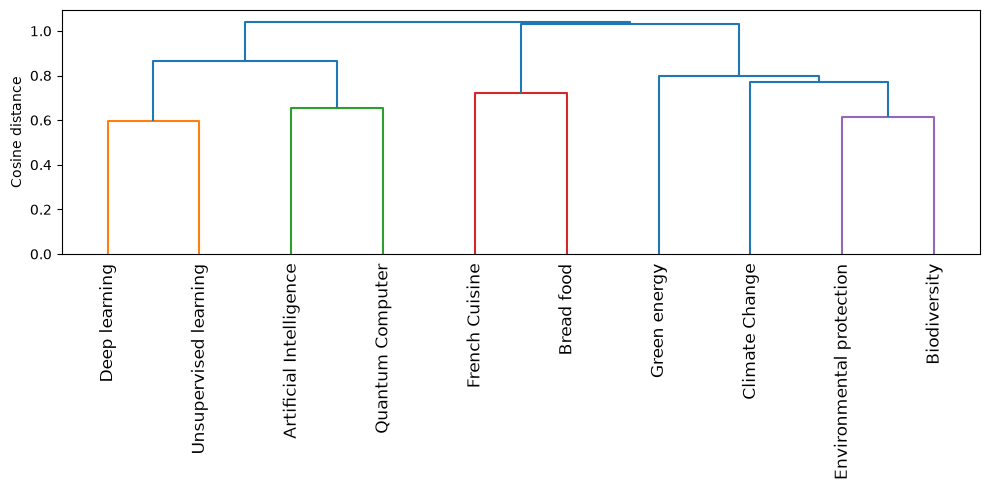

In [51]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
Z = linkage(emb_sents, method="complete", metric="cosine")

plt.figure(figsize=(10, 5))
dendrogram(Z, labels=wiki_df["wiki query"].tolist(), leaf_rotation=90)
plt.ylabel("Cosine distance")
plt.tight_layout()
plt.show()

In [52]:
hier_emb_labels = fcluster(Z, t=3, criterion="maxclust")

In [53]:
wiki_df["emb_hierarchical"] = hier_emb_labels
wiki_df

,wiki query,text,n_words,bow_kmeans,emb_kmeans,emb_dbscan,emb_hierarchical
0,Artificial Intelligence,artificial intelligence ai is the capability of computational systems to perform tasks typically associated with human intelligence such as learning reasoning problem-solving perception and decision-making,25,1,2,0,1
1,Deep learning,in machine learning deep learning dl focuses on utilizing multilayered neural networks to perform tasks such as classification regression and representation learning,22,2,2,0,1
2,Unsupervised learning,unsupervised learning is a framework in machine learning where in contrast to supervised learning algorithms learn patterns exclusively from unlabeled data,21,2,2,0,1
3,Quantum Computer,a quantum computer is a computer that represents and processes information using quantum states,14,0,0,0,1
4,Environmental protection,environmental protection or environment protection refers to the taking of measures to protect the natural environment prevent pollution and maintain ecological balance,22,1,1,1,3
5,Climate Change,present-day climate change includes both global warming — the ongoing increase in global average temperature — and its wider effects on earth climate system,24,1,1,1,3
6,Green energy,energy is sustainable if it meets the needs of the present without compromising the ability of future generations to meet their own needs,23,1,1,1,3
7,Biodiversity,biodiversity is the variability of life on earth,8,1,1,1,3
8,French Cuisine,french cuisine is the cooking traditions and practices of france,10,1,1,2,2
9,Bread food,bread is a baked food product made from water flour and often yeast,13,1,0,2,2


<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

### 1.6 Discussion
rubric={reasoning}

<div class="alert alert-info">

**Your tasks:**

Reflect on and discuss the clustering results of the methods you explored in the previous exercises, focusing on the following points:    
- effect of input representation on clustering results

- whether the clustering results match with your intuitions and the challenges associated with getting the desired clustering results with each method

</div>

<div class="alert alert-warning">

Solution_1.6
    
</div>

_Points:_ 4

The initial clustering with the CountVectorizer representation of the text feature caused for a strange and unintuitive clustering with KMeans clustering. These results can likely be attributed to the lack of semantic representation in the transformed data. CountVectorizer only keeps track of the unique instances of each word, as well as the count of each of the words, which is often not sufficient to represent the meaning of a sentence well, particularly when it comes to keeping track of the order of a sentence. From the clustering results below, we can see that the label 1 was overclassified compared to our intuition, likely due to the similarities in the occurrences of words despite the topics being unrelated to one another. This is drastically improved once we introduced the 'all-MiniLM-L6-v2' transformer to represent the sentence structure. While I do not fully understand how this pretrained transformer works, what we do know is that this transformer is better able to capture semantic meaning in sentences that CountVectorizer severely lacked. This improved the clustering marginally, with the cluster labels being more aligned with the desired [4, 4, 2] that we outlined at the start of the exercise, but still makes a few mischaracterizations, specifically with grouping french cuisine with the sustainability clusters and grouping quantum computer and bread food together. These errors suggest that the KMeans loss function of least squares distance is a poor loss function for this particular problem (I accidentally put distance as the metric for DBSCAN and the results it produced were horrendous so we can be fairly sure that distance is a poor metric to minimize). The remaining two cluster models DBSCAN and hierarchical clustering both produced near identical results, only differing in the labels that were assigned to each cluster. However, both of these models split the queries into the exact clusters that were outline at the beginning of the exercise, which is irrelevant as the cluster labels in unsupervised learning are arbitrary. One final note is that these clustering results are compared to the labels that I assigned at the beginning, but in reality there are no "correct" answers, and we have to interpret the results of a model on a case by case basis. 

In [62]:
print("Clustering Results from bow kmeans:")
print(wiki_df[['wiki query', 'bow_kmeans']])

print("\nClustering Results from embeddings kmeans:")
print(wiki_df[['wiki query', 'emb_kmeans']])

print("\nClustering Results from embeddings dbscan:")
print(wiki_df[['wiki query', 'emb_dbscan']])

print("\nClustering Results from embeddings hierarchical:")
print(wiki_df[['wiki query', 'emb_hierarchical']])


Clustering Results from bow kmeans:
                 wiki query  bow_kmeans
0  Artificial Intelligence   1         
1  Deep learning             2         
2  Unsupervised learning     2         
3  Quantum Computer          0         
4  Environmental protection  1         
5  Climate Change            1         
6  Green energy              1         
7  Biodiversity              1         
8  French Cuisine            1         
9  Bread food                1         

Clustering Results from embeddings kmeans:
                 wiki query  emb_kmeans
0  Artificial Intelligence   2         
1  Deep learning             2         
2  Unsupervised learning     2         
3  Quantum Computer          0         
4  Environmental protection  1         
5  Climate Change            1         
6  Green energy              1         
7  Biodiversity              1         
8  French Cuisine            1         
9  Bread food                0         

Clustering Results from embeddings dbsc

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

### 1.7 Visualizing clusters
rubric={points:4}


One approach to working with unlabeled data is visualization. That said, our data is high-dimensional, making it challenging to visualize. Take sentence embedding representation as an example: each instance is depicted in 768 dimensions. To visualize such high-dimensional data, we can employ dimensionality reduction techniques to extract the most significant 2 or 3 components, and then visualize this low-dimensional data.

Given data as a `numpy` array and corresponding cluster assignments, the `plot_umap_clusters` function below transforms the data by applying dimensionality reduction technique called [UMAP](https://umap-learn.readthedocs.io/en/latest/) to it and plots the transformed data with different colours for different clusters. 

> *Note: At this point we are using this function only for visualization and you are not expected to understand the UMAP part.* 

You'll have to install the `umap-learn` package in the course conda environment either with `conda` or `pip`, as described in the [documentation](https://umap-learn.readthedocs.io/en/latest/index.html). 

```
> conda activate cpsc330
> conda install -c conda-forge umap-learn
```
or

```
> conda activate cpsc330
> pip install umap-learn 
```

If you get an error with the import below try

```
pip install --upgrade numba umap-learn
```

<div class="alert alert-info">
    
**Your tasks:**

1. Visualize the clusters created by the methods above using `plot_umap_clusters` function below. In other words, visualize clusters identified by each of the methods below. 
    - K-Means with bag-of-words representation 
    - K-Means with sentence embedding representation
    - DBSCAN with sentence embedding representation 
    - Flat cluster of hierarchical clustering with sentence embedding representation
</div>

In [63]:
import umap

In [64]:
def plot_umap_clusters(
    data,
    cluster_labels,
    raw_texts=None,
    show_labels=False,
    point_size=50,
    n_neighbors=15,
    title="UMAP Visualization",
    ignore_noise=False,
):
    """
    Perform dimensionality reduction using UMAP and visualize the resulting clusters.

    Parameters
    ----------
    data : np.ndarray
        Feature matrix to be reduced.
    cluster_labels : array-like
        Cluster label for each data point.
    raw_texts : list of str, optional
        Original texts corresponding to the data points (used when show_labels=True).
    show_labels : bool, default=False
        Whether to annotate points with text labels.
    point_size : int, default=50
        Size of the scatterplot points.
    n_neighbors : int, default=15
        Number of neighbors used in UMAP.
    title : str, default="UMAP Visualization"
        Title of the plot.
    ignore_noise : bool, default=False
        Whether to exclude points labeled as noise (-1).

    Returns
    -------
    None
    """
    reducer = umap.UMAP(n_neighbors=n_neighbors, random_state=42)
    embedding = reducer.fit_transform(data)

    df = pd.DataFrame(embedding, columns=["dim1", "dim2"])
    df["cluster"] = cluster_labels

    if ignore_noise:
        df = df[df["cluster"] != -1]

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.set_title(title)

    scatter = ax.scatter(
        df["dim1"], df["dim2"],
        c=df["cluster"], cmap="tab20b", s=point_size
    )

    ax.legend(*scatter.legend_elements(), title="Clusters", loc="best")

    if show_labels and raw_texts is not None:
        for (x, y, text) in zip(df["dim1"], df["dim2"], raw_texts):
            ax.annotate(" ".join(text.split()[:10]), (x, y), fontsize=8)

    plt.show()


<div class="alert alert-warning">

Solution_1.7
    
</div>

_Points:_ 4

/Users/johnn/Desktop/Here We Go Again/330/CPSC330-/assignment6/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/johnn/Desktop/Here We Go Again/330/CPSC330-/assignment6/.venv/lib/python3.12/site-packages/umap/umap_.py:2462: UserWarning: n_neighbors is larger than the dataset size; truncating to X.shape[0] - 1
  warn(


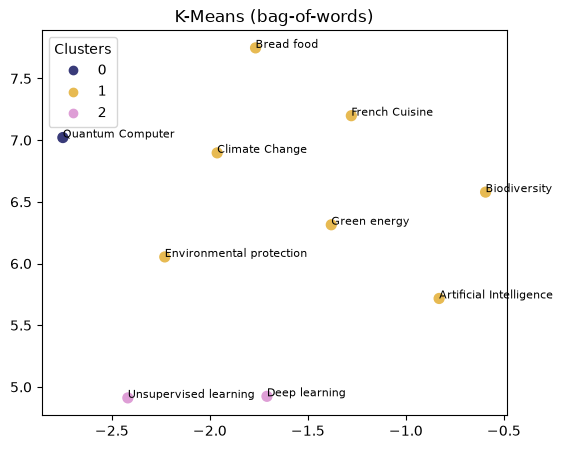

/Users/johnn/Desktop/Here We Go Again/330/CPSC330-/assignment6/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/johnn/Desktop/Here We Go Again/330/CPSC330-/assignment6/.venv/lib/python3.12/site-packages/umap/umap_.py:2462: UserWarning: n_neighbors is larger than the dataset size; truncating to X.shape[0] - 1
  warn(


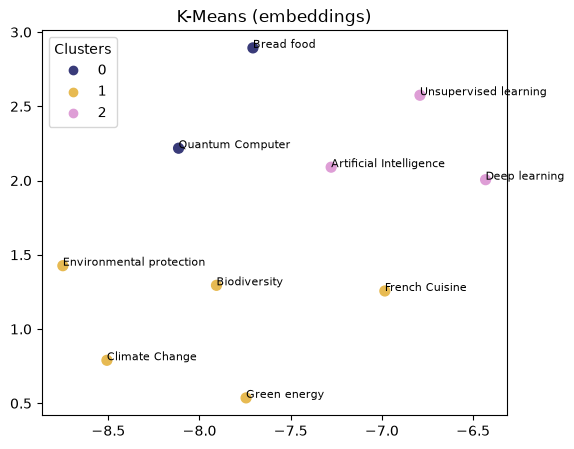

/Users/johnn/Desktop/Here We Go Again/330/CPSC330-/assignment6/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/johnn/Desktop/Here We Go Again/330/CPSC330-/assignment6/.venv/lib/python3.12/site-packages/umap/umap_.py:2462: UserWarning: n_neighbors is larger than the dataset size; truncating to X.shape[0] - 1
  warn(


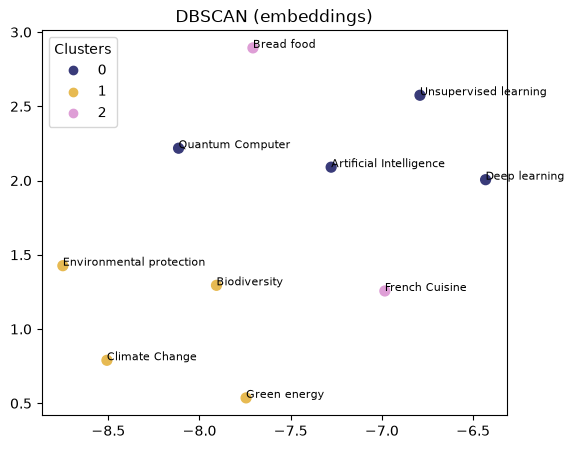

/Users/johnn/Desktop/Here We Go Again/330/CPSC330-/assignment6/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/johnn/Desktop/Here We Go Again/330/CPSC330-/assignment6/.venv/lib/python3.12/site-packages/umap/umap_.py:2462: UserWarning: n_neighbors is larger than the dataset size; truncating to X.shape[0] - 1
  warn(


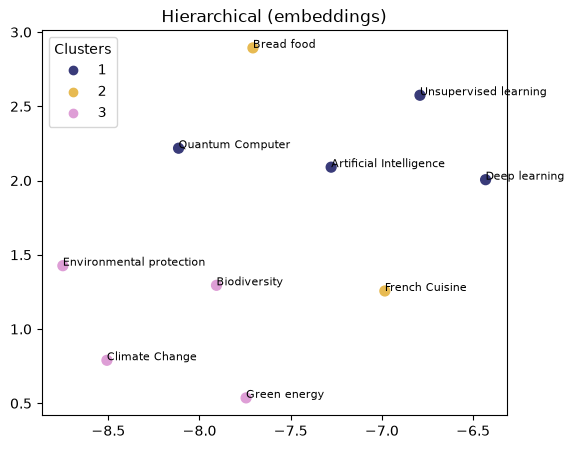

In [71]:
clusters = [wiki_df['bow_kmeans'], 
            wiki_df['emb_kmeans'], 
            wiki_df['emb_dbscan'], 
            wiki_df['emb_hierarchical']]

# Bag-of-words matrix (the same one the KMeans pipeline used)
X_bow = pipe[0].transform(wiki_df["text"]).toarray()
# if your pipeline used the column transformer version, use pipe[0].transform(wiki_df).toarray()

methods = [
    ("K-Means (bag-of-words)",       X_bow, wiki_df["bow_kmeans"]),
    ("K-Means (embeddings)",         emb_sent_df, wiki_df["emb_kmeans"]),
    ("DBSCAN (embeddings)",          emb_sent_df, wiki_df["emb_dbscan"]),
    ("Hierarchical (embeddings)",    emb_sent_df, wiki_df["emb_hierarchical"]),
]

for title, X, labels in methods:
    plot_umap_clusters(
        data=X,
        cluster_labels=labels,
        raw_texts=wiki_df["wiki query"].tolist(),
        show_labels=True,
        title=title,
    )

<!-- END QUESTION -->

<br><br><br><br>

Before submitting your assignment, please make sure you have followed all the instructions in the Submission Instructions section at the top.

Here is a quick checklist before submitting:

- [ ] Restart kernel, clear outputs, and run all cells from top to bottom.
- [ ] `.ipynb` file runs without errors and contains all outputs.
- [ ] Return to the PrairieLearn question page and click **Save only** to check the rendered notebook preview.
- [ ] When the preview looks correct, click **Save & Grade**.
- [ ] If you are working in a group, confirm your PrairieLearn group membership is correct.
- [ ] Execution numbers start at **1** and are in order.
- [ ] Review the CPSC 330 homework instructions on the course website for details on the grading process.

![](img/eva-well-done.png)